In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from DataTransformation import LowPassFilter, PrincipalComponentAnalysis
from TemporalAbstraction import NumericalAbstraction
from FrequencyAbtraction import FourierTransformation
from sklearn.cluster import KMeans

In [201]:
df=pd.read_pickle(r"../../data/interim/02_outliers_removed_chauvenet.pkl")
df

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set
epoch (ms),,,,,,,,,,
2019-01-11 15:08:05.200,0.013500,0.977000,-0.071000,-1.8904,2.4392,0.9388,B,bench,heavy,30
2019-01-11 15:08:05.400,-0.001500,0.970500,-0.079500,-1.6826,-0.8904,2.1708,B,bench,heavy,30
2019-01-11 15:08:05.600,0.001333,0.971667,-0.064333,2.5608,-0.2560,-1.4146,B,bench,heavy,30
2019-01-11 15:08:05.800,-0.024000,0.957000,-0.073500,8.0610,-4.5244,-2.0730,B,bench,heavy,30
2019-01-11 15:08:06.000,-0.028000,0.957667,-0.115000,2.4390,-1.5486,-3.6098,B,bench,heavy,30
...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048000,-1.041500,-0.076500,1.4146,-5.6218,0.2926,E,row,medium,90
2019-01-20 17:33:27.200,-0.037000,-1.030333,-0.053333,-2.7684,-0.5854,2.2440,E,row,medium,90
2019-01-20 17:33:27.400,-0.060000,-1.031000,-0.082000,2.8416,-5.1342,-0.1220,E,row,medium,90


In [202]:
predictor_columns=list(df.columns[:6])

In [203]:
predictor_columns

['acc_x', 'acc_y', 'acc_z', 'gyr_x', 'gyr_y', 'gyr_z']

In [204]:
plt.style.use("fivethirtyeight")
plt.rcParams["figure.figsize"]=(20,5)
plt.rcParams["figure.dpi"]=100
plt.rcParams["lines.linewidth"]=2

In [205]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9009 entries, 2019-01-11 15:08:05.200000 to 2019-01-20 17:33:27.800000
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   acc_x        9005 non-null   float64
 1   acc_y        8998 non-null   float64
 2   acc_z        8999 non-null   float64
 3   gyr_x        8984 non-null   float64
 4   gyr_y        8938 non-null   float64
 5   gyr_z        8945 non-null   float64
 6   participant  9009 non-null   object 
 7   label        9009 non-null   object 
 8   category     9009 non-null   object 
 9   set          9009 non-null   int32  
dtypes: float64(6), int32(1), object(3)
memory usage: 739.0+ KB


In [206]:
for col in predictor_columns:
    df[col]=df[col].interpolate()#interpolate the data and fill missing values

In [207]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9009 entries, 2019-01-11 15:08:05.200000 to 2019-01-20 17:33:27.800000
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   acc_x        9009 non-null   float64
 1   acc_y        9009 non-null   float64
 2   acc_z        9009 non-null   float64
 3   gyr_x        9009 non-null   float64
 4   gyr_y        9009 non-null   float64
 5   gyr_z        9009 non-null   float64
 6   participant  9009 non-null   object 
 7   label        9009 non-null   object 
 8   category     9009 non-null   object 
 9   set          9009 non-null   int32  
dtypes: float64(6), int32(1), object(3)
memory usage: 739.0+ KB


<AxesSubplot: xlabel='epoch (ms)'>

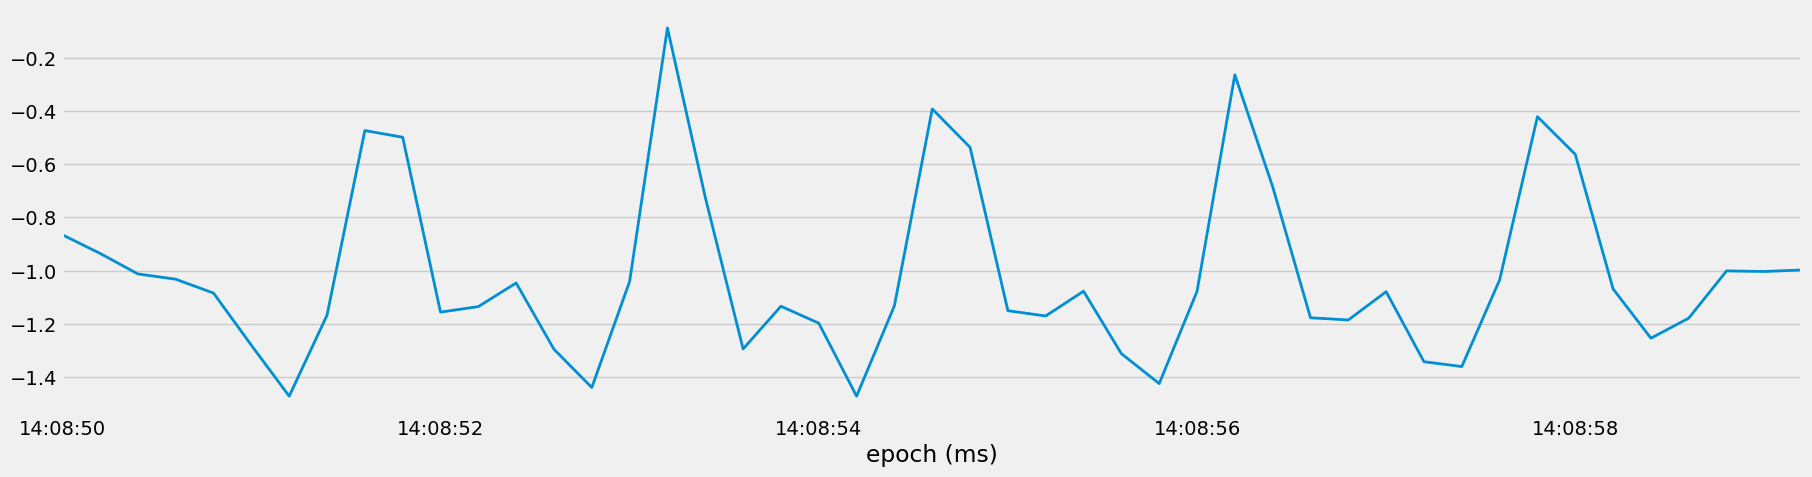

In [208]:
df[df["set"]==50]["acc_y"].plot()

In [209]:
duration=df[df["set"]==1].index[-1]-df[df["set"]==1].index[0]
duration.seconds

16

In [210]:
#now we will calculate the duration for each set

In [211]:
for s in df["set"].unique():
    duration=df[df["set"]==s].index[-1]-df[df["set"]==s].index[0]
    df.loc[(df["set"]==s),"duration"]=duration.seconds

In [212]:
df

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,duration
epoch (ms),,,,,,,,,,,
2019-01-11 15:08:05.200,0.013500,0.977000,-0.071000,-1.8904,2.4392,0.9388,B,bench,heavy,30,16.0
2019-01-11 15:08:05.400,-0.001500,0.970500,-0.079500,-1.6826,-0.8904,2.1708,B,bench,heavy,30,16.0
2019-01-11 15:08:05.600,0.001333,0.971667,-0.064333,2.5608,-0.2560,-1.4146,B,bench,heavy,30,16.0
2019-01-11 15:08:05.800,-0.024000,0.957000,-0.073500,8.0610,-4.5244,-2.0730,B,bench,heavy,30,16.0
2019-01-11 15:08:06.000,-0.028000,0.957667,-0.115000,2.4390,-1.5486,-3.6098,B,bench,heavy,30,16.0
...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048000,-1.041500,-0.076500,1.4146,-5.6218,0.2926,E,row,medium,90,19.0
2019-01-20 17:33:27.200,-0.037000,-1.030333,-0.053333,-2.7684,-0.5854,2.2440,E,row,medium,90,19.0
2019-01-20 17:33:27.400,-0.060000,-1.031000,-0.082000,2.8416,-5.1342,-0.1220,E,row,medium,90,19.0


In [213]:
df[df["duration"]==16]

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,duration
epoch (ms),,,,,,,,,,,
2019-01-11 15:08:05.200,0.013500,0.977000,-0.071000,-1.8904,2.4392,0.9388,B,bench,heavy,30,16.0
2019-01-11 15:08:05.400,-0.001500,0.970500,-0.079500,-1.6826,-0.8904,2.1708,B,bench,heavy,30,16.0
2019-01-11 15:08:05.600,0.001333,0.971667,-0.064333,2.5608,-0.2560,-1.4146,B,bench,heavy,30,16.0
2019-01-11 15:08:05.800,-0.024000,0.957000,-0.073500,8.0610,-4.5244,-2.0730,B,bench,heavy,30,16.0
2019-01-11 15:08:06.000,-0.028000,0.957667,-0.115000,2.4390,-1.5486,-3.6098,B,bench,heavy,30,16.0
...,...,...,...,...,...,...,...,...,...,...,...
2019-01-18 17:04:06.800,0.123000,0.802333,0.541333,3.9510,-1.1220,0.4634,D,squat,heavy,62,16.0
2019-01-18 17:04:07.000,0.118500,0.812500,0.535000,-3.4390,-0.8536,0.6222,D,squat,heavy,62,16.0
2019-01-18 17:04:07.200,0.116000,0.801000,0.543333,-1.3172,-0.7806,1.4754,D,squat,heavy,62,16.0


In [214]:
duration_df=df.groupby(["category"])["duration"].mean()
duration_df

category
heavy       14.743501
medium      24.942529
sitting     33.000000
standing    39.000000
Name: duration, dtype: float64

In [215]:
df_lowpass=df.copy()
LowPass=LowPassFilter()

In [216]:
fs=1000/200
cutoff=1
df_lowpass=LowPass.low_pass_filter(df_lowpass,"acc_y",fs,cutoff,order=5)
df_lowpass

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,duration,acc_y_lowpass
epoch (ms),,,,,,,,,,,,
2019-01-11 15:08:05.200,0.013500,0.977000,-0.071000,-1.8904,2.4392,0.9388,B,bench,heavy,30,16.0,0.977022
2019-01-11 15:08:05.400,-0.001500,0.970500,-0.079500,-1.6826,-0.8904,2.1708,B,bench,heavy,30,16.0,0.962269
2019-01-11 15:08:05.600,0.001333,0.971667,-0.064333,2.5608,-0.2560,-1.4146,B,bench,heavy,30,16.0,0.966368
2019-01-11 15:08:05.800,-0.024000,0.957000,-0.073500,8.0610,-4.5244,-2.0730,B,bench,heavy,30,16.0,0.979343
2019-01-11 15:08:06.000,-0.028000,0.957667,-0.115000,2.4390,-1.5486,-3.6098,B,bench,heavy,30,16.0,0.966609
...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048000,-1.041500,-0.076500,1.4146,-5.6218,0.2926,E,row,medium,90,19.0,-1.010877
2019-01-20 17:33:27.200,-0.037000,-1.030333,-0.053333,-2.7684,-0.5854,2.2440,E,row,medium,90,19.0,-0.986139
2019-01-20 17:33:27.400,-0.060000,-1.031000,-0.082000,2.8416,-5.1342,-0.1220,E,row,medium,90,19.0,-1.026145


ohp


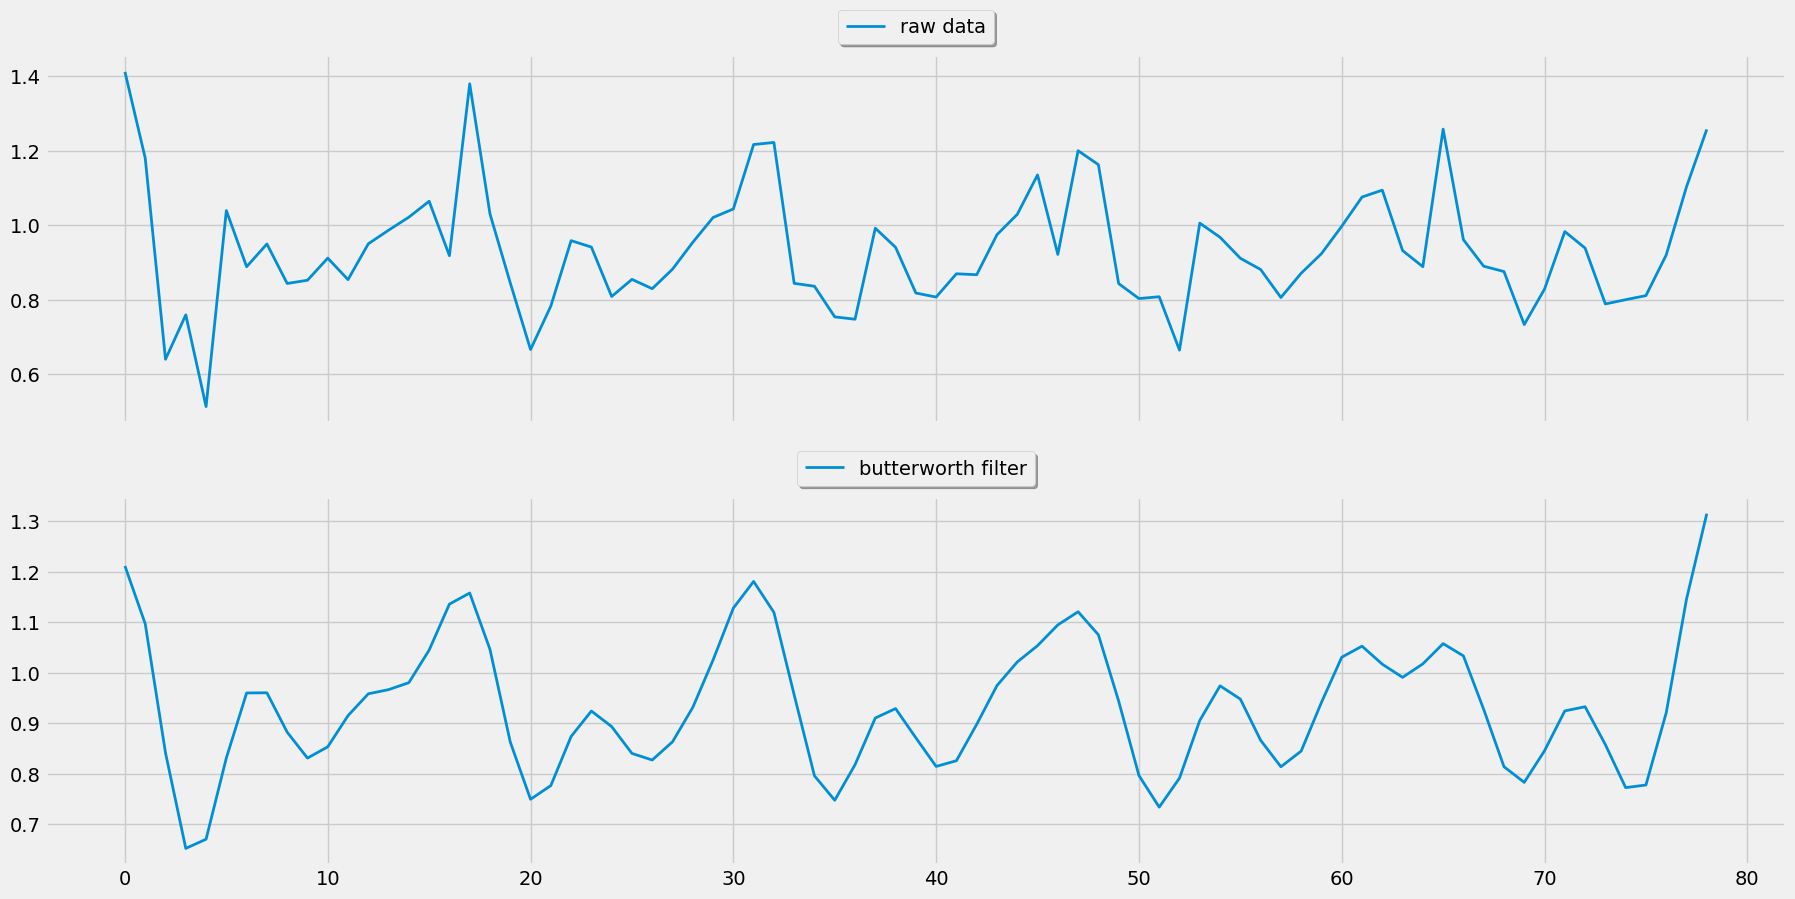

In [217]:
subset=df_lowpass[df_lowpass["set"]==45]
print(subset["label"][0])
fig, ax = plt.subplots(nrows=2, sharex=True, figsize=(20, 10))
ax[0].plot(subset["acc_y"].reset_index(drop=True), label="raw data")
ax[1].plot(subset["acc_y_lowpass"].reset_index(drop=True), label="butterworth filter")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), fancybox=True, shadow=True)
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), fancybox=True, shadow=True)

for col in predictor_columns:
    df_lowpass = LowPass.low_pass_filter(df_lowpass, col, fs, cutoff, order=5)
    df_lowpass[col] = df_lowpass[col + "_lowpass"]
    del df_lowpass[col + "_lowpass"]

In [218]:
df_lowpass

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,duration
epoch (ms),,,,,,,,,,,
2019-01-11 15:08:05.200,0.013501,0.977022,-0.070982,-1.900465,2.437780,0.940880,B,bench,heavy,30,16.0
2019-01-11 15:08:05.400,-0.004111,0.962269,-0.075309,1.437860,-0.522120,0.476150,B,bench,heavy,30,16.0
2019-01-11 15:08:05.600,-0.014143,0.966368,-0.074978,1.633730,-2.981339,1.302906,B,bench,heavy,30,16.0
2019-01-11 15:08:05.800,-0.013047,0.979343,-0.074482,1.092197,-3.156357,0.501259,B,bench,heavy,30,16.0
2019-01-11 15:08:06.000,-0.010429,0.966609,-0.088632,5.070302,0.248676,-5.951031,B,bench,heavy,30,16.0
...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,19.0
2019-01-20 17:33:27.200,-0.046788,-0.986139,-0.055736,2.208068,-3.456089,0.133057,E,row,medium,90,19.0
2019-01-20 17:33:27.400,-0.045416,-1.026145,-0.056200,-2.408598,-1.581380,1.525886,E,row,medium,90,19.0


In [219]:
#PCA principal component analysis

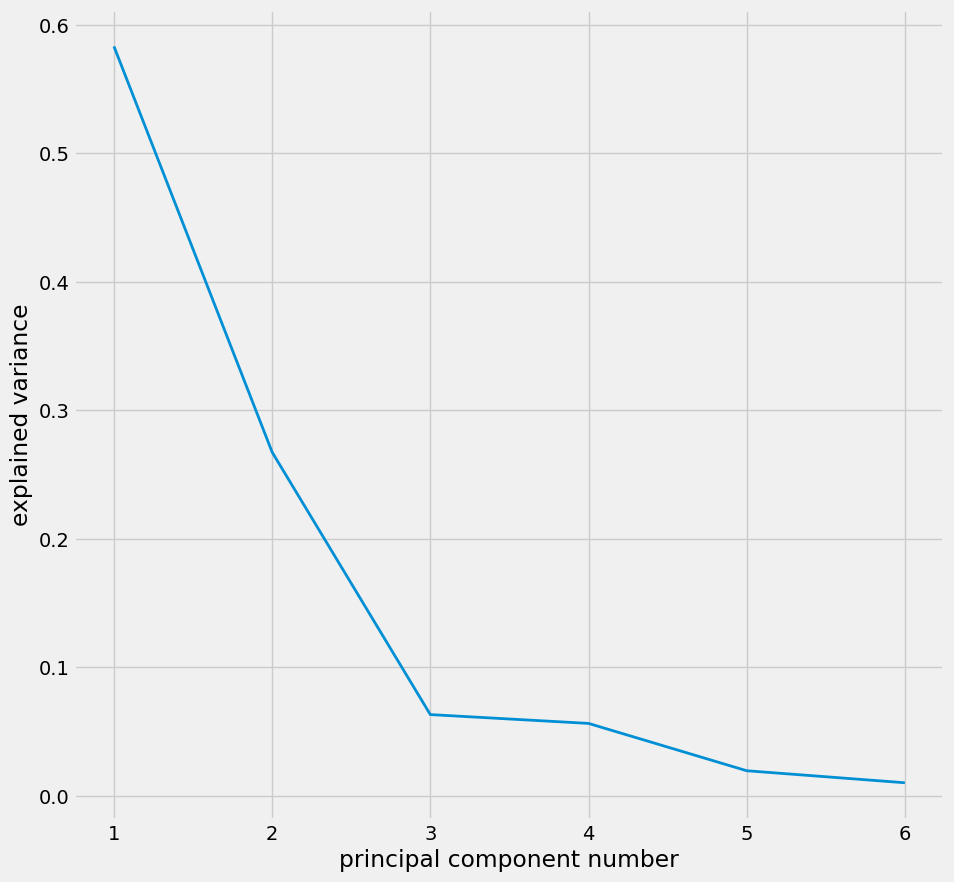

<AxesSubplot: xlabel='epoch (ms)'>

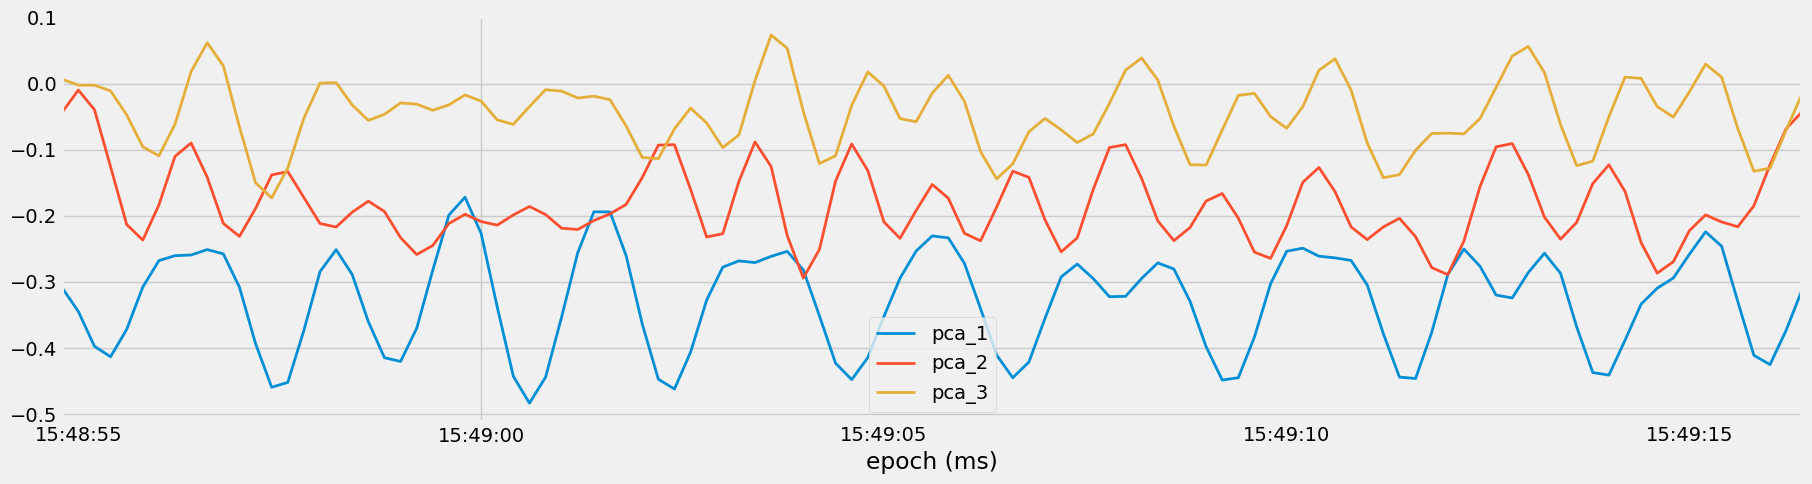

In [220]:
df_pca = df_lowpass.copy()
PCA = PrincipalComponentAnalysis()

pc_values = PCA.determine_pc_explained_variance(df_pca, predictor_columns)

plt.figure(figsize=(10, 10))
plt.plot(range(1, len(predictor_columns) + 1), pc_values)
plt.xlabel("principal component number")
plt.ylabel("explained variance")
plt.show()

df_pca = PCA.apply_pca(df_pca, predictor_columns, 3)

subset = df_pca[df_pca["set"] == 35]
subset[["pca_1", "pca_2", "pca_3"]].plot()

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,duration,pca_1,pca_2,pca_3,acc_r,gyr_r
epoch (ms),,,,,,,,,,,,,,,,
2019-01-11 15:08:05.200,0.013501,0.977022,-0.070982,-1.900465,2.437780,0.940880,B,bench,heavy,30,16.0,-0.322491,-0.076144,0.068888,0.979690,3.231067
2019-01-11 15:08:05.400,-0.004111,0.962269,-0.075309,1.437860,-0.522120,0.476150,B,bench,heavy,30,16.0,-0.318852,-0.082448,0.065940,0.965221,1.602114
2019-01-11 15:08:05.600,-0.014143,0.966368,-0.074978,1.633730,-2.981339,1.302906,B,bench,heavy,30,16.0,-0.321133,-0.083940,0.061698,0.969376,3.640745
2019-01-11 15:08:05.800,-0.013047,0.979343,-0.074482,1.092197,-3.156357,0.501259,B,bench,heavy,30,16.0,-0.325564,-0.083004,0.062098,0.982258,3.377387
2019-01-11 15:08:06.000,-0.010429,0.966609,-0.088632,5.070302,0.248676,-5.951031,B,bench,heavy,30,16.0,-0.321081,-0.091340,0.072389,0.970720,7.822057
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,19.0,0.364382,-0.160191,-0.044117,1.014989,8.915412
2019-01-20 17:33:27.200,-0.046788,-0.986139,-0.055736,2.208068,-3.456089,0.133057,E,row,medium,90,19.0,0.356247,-0.146029,-0.054218,0.988820,4.103391
2019-01-20 17:33:27.400,-0.045416,-1.026145,-0.056200,-2.408598,-1.581380,1.525886,E,row,medium,90,19.0,0.370106,-0.147280,-0.062181,1.028686,3.260435


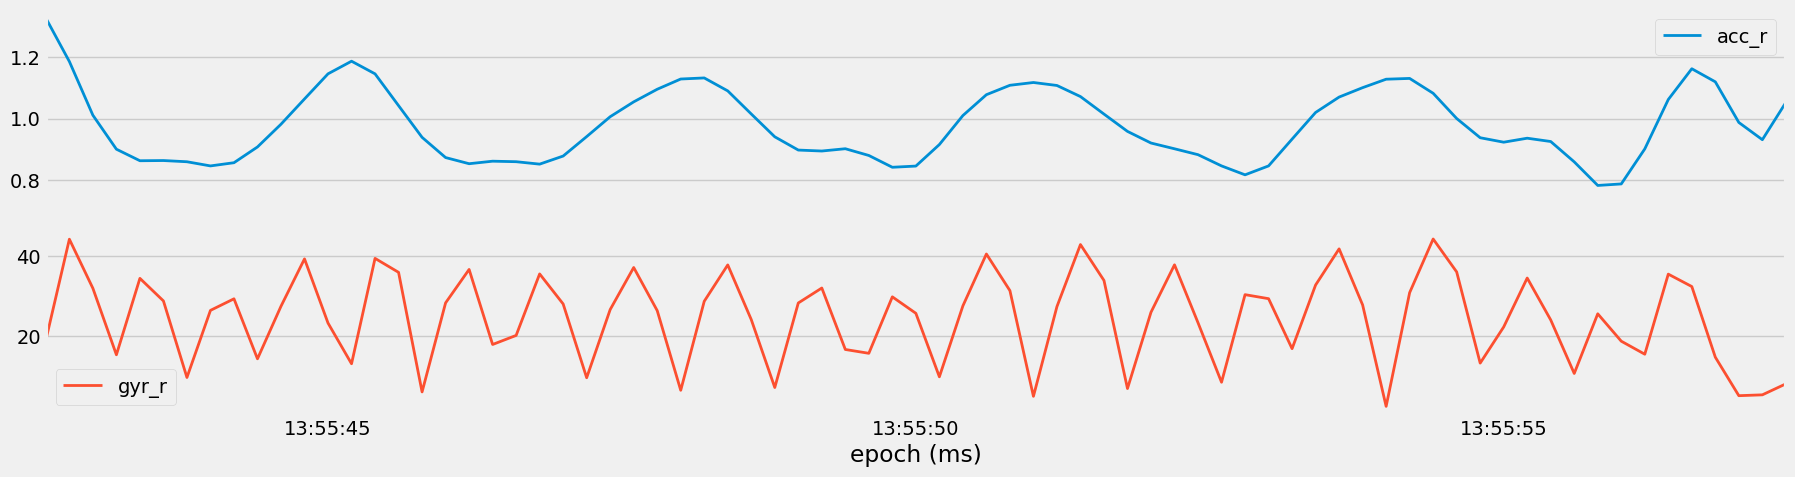

In [221]:
df_squared = df_pca.copy()

acc_r = df_squared["acc_x"] ** 2 + df_squared["acc_y"] ** 2 + df_squared["acc_z"] ** 2
gyr_r = df_squared["gyr_x"] ** 2 + df_squared["gyr_y"] ** 2 + df_squared["gyr_z"] ** 2

df_squared["acc_r"] = np.sqrt(acc_r)
df_squared["gyr_r"] = np.sqrt(gyr_r)

subset = df_squared[df_squared["set"] == 14]

subset[["acc_r", "gyr_r"]].plot(subplots=True)

df_squared

In [222]:
df_temporal=df_squared.copy()
NumAbs = NumericalAbstraction()

predictor_columns=predictor_columns + ["acc_r","gyr_r"]
ws=int(1000/200)
for col in predictor_columns:
    df_temporal=NumAbs.abstract_numerical(df_temporal,[col],ws,"mean")
    df_temporal=NumAbs.abstract_numerical(df_temporal,[col],ws,"std")

In [223]:
df_temporal

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,...,gyr_x_temp_mean_ws_5,gyr_x_temp_std_ws_5,gyr_y_temp_mean_ws_5,gyr_y_temp_std_ws_5,gyr_z_temp_mean_ws_5,gyr_z_temp_std_ws_5,acc_r_temp_mean_ws_5,acc_r_temp_std_ws_5,gyr_r_temp_mean_ws_5,gyr_r_temp_std_ws_5
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:05.200,0.013501,0.977022,-0.070982,-1.900465,2.437780,0.940880,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.400,-0.004111,0.962269,-0.075309,1.437860,-0.522120,0.476150,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.600,-0.014143,0.966368,-0.074978,1.633730,-2.981339,1.302906,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.800,-0.013047,0.979343,-0.074482,1.092197,-3.156357,0.501259,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:06.000,-0.010429,0.966609,-0.088632,5.070302,0.248676,-5.951031,B,bench,heavy,30,...,1.466725,2.213266,-0.794672,2.096219,-0.545967,2.719749,0.973453,0.006454,3.934674,2.070971
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,...,-11.188688,15.180812,0.342197,4.435035,7.086911,5.835204,1.072404,0.096242,18.278373,11.207382
2019-01-20 17:33:27.200,-0.046788,-0.986139,-0.055736,2.208068,-3.456089,0.133057,E,row,medium,90,...,-4.903996,12.722496,-1.460787,3.723107,4.423421,5.341121,1.086615,0.075334,12.571093,9.590013
2019-01-20 17:33:27.400,-0.045416,-1.026145,-0.056200,-2.408598,-1.581380,1.525886,E,row,medium,90,...,0.060610,6.225381,-2.767009,1.984758,2.050517,2.914563,1.069795,0.076983,7.073825,3.607623


In [224]:
df_temporal_list = []
for s in df_temporal["set"].unique():
    subset = df_temporal[df_temporal["set"] == s].copy()
    for col in predictor_columns:
        subset = NumAbs.abstract_numerical(subset, [col], ws, "mean")
        subset = NumAbs.abstract_numerical(subset, [col], ws, "std")
    df_temporal_list.append(subset)

df_temporal = pd.concat(df_temporal_list)

In [225]:
df_temporal.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9009 entries, 2019-01-11 15:08:05.200000 to 2019-01-20 17:33:27.800000
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   acc_x                 9009 non-null   float64
 1   acc_y                 9009 non-null   float64
 2   acc_z                 9009 non-null   float64
 3   gyr_x                 9009 non-null   float64
 4   gyr_y                 9009 non-null   float64
 5   gyr_z                 9009 non-null   float64
 6   participant           9009 non-null   object 
 7   label                 9009 non-null   object 
 8   category              9009 non-null   object 
 9   set                   9009 non-null   int32  
 10  duration              9009 non-null   float64
 11  pca_1                 9009 non-null   float64
 12  pca_2                 9009 non-null   float64
 13  pca_3                 9009 non-null   float64
 14  acc_r                 

In [226]:
df_temporal.columns

Index(['acc_x', 'acc_y', 'acc_z', 'gyr_x', 'gyr_y', 'gyr_z', 'participant',
       'label', 'category', 'set', 'duration', 'pca_1', 'pca_2', 'pca_3',
       'acc_r', 'gyr_r', 'acc_x_temp_mean_ws_5', 'acc_x_temp_std_ws_5',
       'acc_y_temp_mean_ws_5', 'acc_y_temp_std_ws_5', 'acc_z_temp_mean_ws_5',
       'acc_z_temp_std_ws_5', 'gyr_x_temp_mean_ws_5', 'gyr_x_temp_std_ws_5',
       'gyr_y_temp_mean_ws_5', 'gyr_y_temp_std_ws_5', 'gyr_z_temp_mean_ws_5',
       'gyr_z_temp_std_ws_5', 'acc_r_temp_mean_ws_5', 'acc_r_temp_std_ws_5',
       'gyr_r_temp_mean_ws_5', 'gyr_r_temp_std_ws_5'],
      dtype='object')

In [227]:
subset[["acc_y","acc_y_temp_std_ws_5","acc_y_temp_mean_ws_5"]]

,acc_y,acc_y_temp_std_ws_5,acc_y_temp_mean_ws_5
epoch (ms),,,
2019-01-20 17:33:08.400,-1.067812,NaN,NaN
2019-01-20 17:33:08.600,-1.074336,NaN,NaN
2019-01-20 17:33:08.800,-1.016169,NaN,NaN
2019-01-20 17:33:09.000,-0.960792,NaN,NaN
2019-01-20 17:33:09.200,-0.996090,0.043091,-1.023040
...,...,...,...
2019-01-20 17:33:27.000,-1.010877,0.097745,-1.067847
2019-01-20 17:33:27.200,-0.986139,0.075078,-1.083183
2019-01-20 17:33:27.400,-1.026145,0.076267,-1.065907


<AxesSubplot: xlabel='epoch (ms)'>

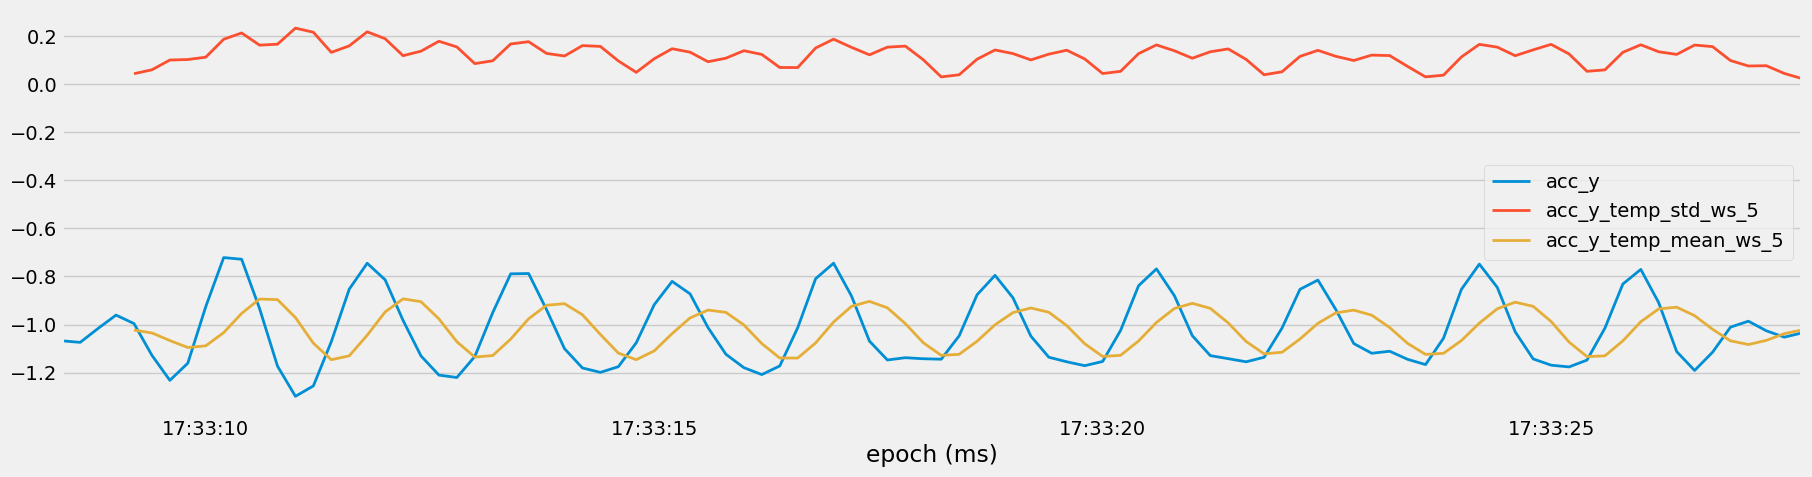

In [228]:
subset[["acc_y","acc_y_temp_std_ws_5","acc_y_temp_mean_ws_5"]].plot()

<AxesSubplot: xlabel='epoch (ms)'>

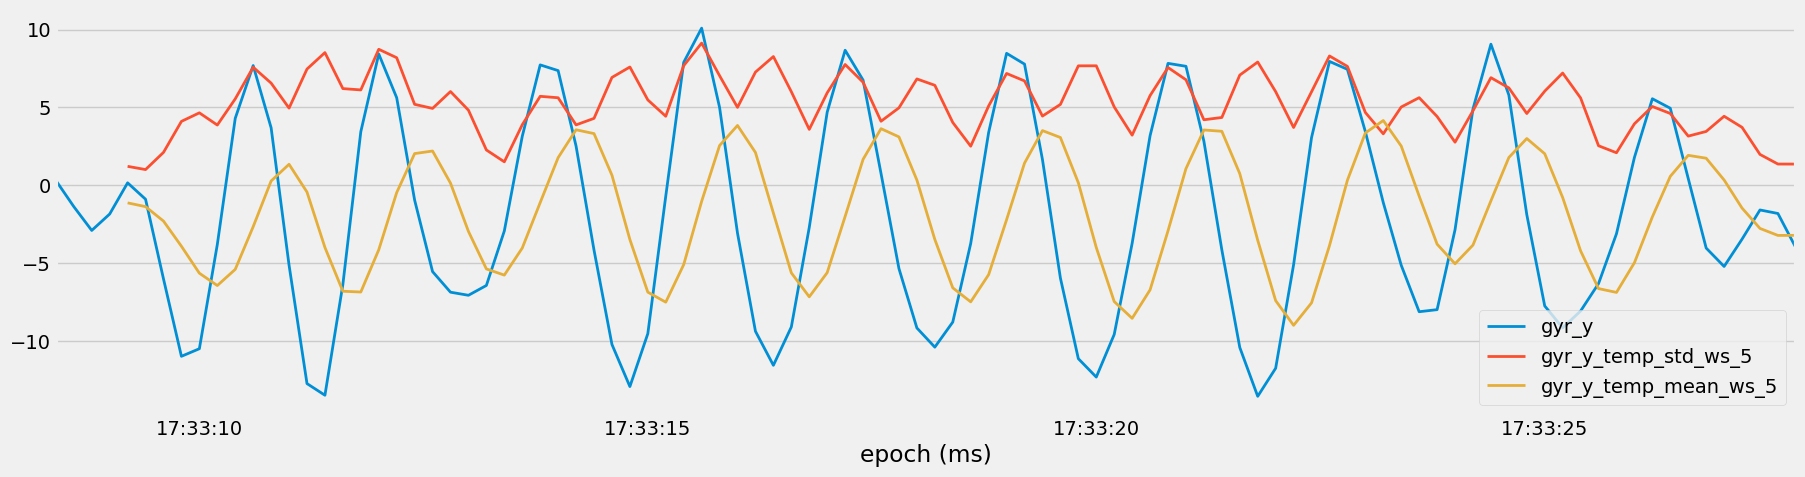

In [229]:
subset[["gyr_y","gyr_y_temp_std_ws_5","gyr_y_temp_mean_ws_5"]].plot()

In [230]:
#frequency features

In [231]:
df_freq = df_temporal.copy().reset_index()
FreqAbs = FourierTransformation()
fs= int(1000/200)
ws=int(2800/200)
df_freq=FreqAbs.abstract_frequency(df_freq,["acc_y"],ws,fs)


In [232]:
df_freq

,epoch (ms),acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,...,acc_y_freq_weighted,acc_y_pse,acc_y_freq_0.0_Hz_ws_14,acc_y_freq_0.357_Hz_ws_14,acc_y_freq_0.714_Hz_ws_14,acc_y_freq_1.071_Hz_ws_14,acc_y_freq_1.429_Hz_ws_14,acc_y_freq_1.786_Hz_ws_14,acc_y_freq_2.143_Hz_ws_14,acc_y_freq_2.5_Hz_ws_14
0,2019-01-11 15:08:05.200,0.013501,0.977022,-0.070982,-1.900465,2.437780,0.940880,B,bench,heavy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-01-11 15:08:05.400,-0.004111,0.962269,-0.075309,1.437860,-0.522120,0.476150,B,bench,heavy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2019-01-11 15:08:05.600,-0.014143,0.966368,-0.074978,1.633730,-2.981339,1.302906,B,bench,heavy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-01-11 15:08:05.800,-0.013047,0.979343,-0.074482,1.092197,-3.156357,0.501259,B,bench,heavy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-01-11 15:08:06.000,-0.010429,0.966609,-0.088632,5.070302,0.248676,-5.951031,B,bench,heavy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9004,2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,...,-0.158639,0.041513,-15.218019,0.038166,1.116381,0.412087,0.097916,0.106633,0.110340,0.111633
9005,2019-01-20 17:33:27.200,-0.046788,-0.986139,-0.055736,2.208068,-3.456089,0.133057,E,row,medium,...,-0.126034,0.049421,-15.455378,-0.332996,1.265634,-0.168479,0.218313,0.145908,0.131135,0.126136
9006,2019-01-20 17:33:27.400,-0.045416,-1.026145,-0.056200,-2.408598,-1.581380,1.525886,E,row,medium,...,-0.031943,0.029544,-15.635918,-0.574154,0.693921,-0.334645,0.112674,0.075088,0.060898,0.055561
9007,2019-01-20 17:33:27.600,-0.044925,-1.052548,-0.061608,-2.376623,-1.808121,1.788398,E,row,medium,...,0.028125,0.011968,-15.657984,-0.555653,-0.171210,0.135379,-0.059022,-0.029423,-0.031277,-0.032707


Applying Fourier transformations to set 30
Applying Fourier transformations to set 1
Applying Fourier transformations to set 31
Applying Fourier transformations to set 3
Applying Fourier transformations to set 9
Applying Fourier transformations to set 32
Applying Fourier transformations to set 10
Applying Fourier transformations to set 33
Applying Fourier transformations to set 11
Applying Fourier transformations to set 34
Applying Fourier transformations to set 35
Applying Fourier transformations to set 15
Applying Fourier transformations to set 36
Applying Fourier transformations to set 16
Applying Fourier transformations to set 37
Applying Fourier transformations to set 17
Applying Fourier transformations to set 27
Applying Fourier transformations to set 38
Applying Fourier transformations to set 28
Applying Fourier transformations to set 29
Applying Fourier transformations to set 6
Applying Fourier transformations to set 65
Applying Fourier transformations to set 67
Applying Fourie

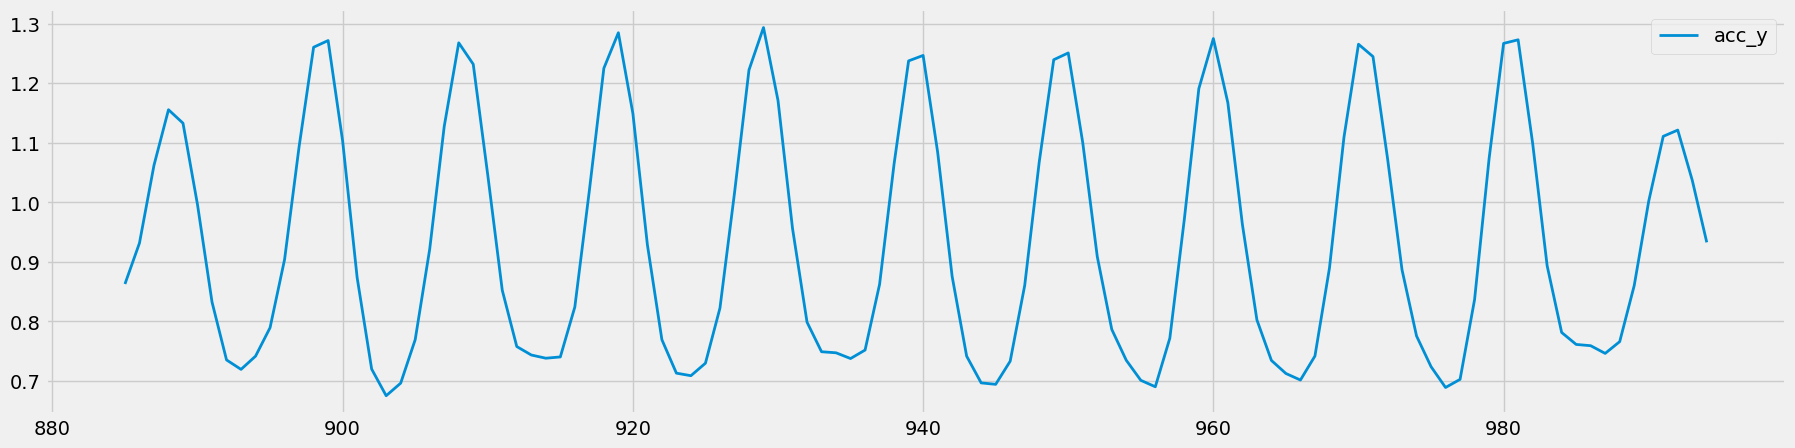

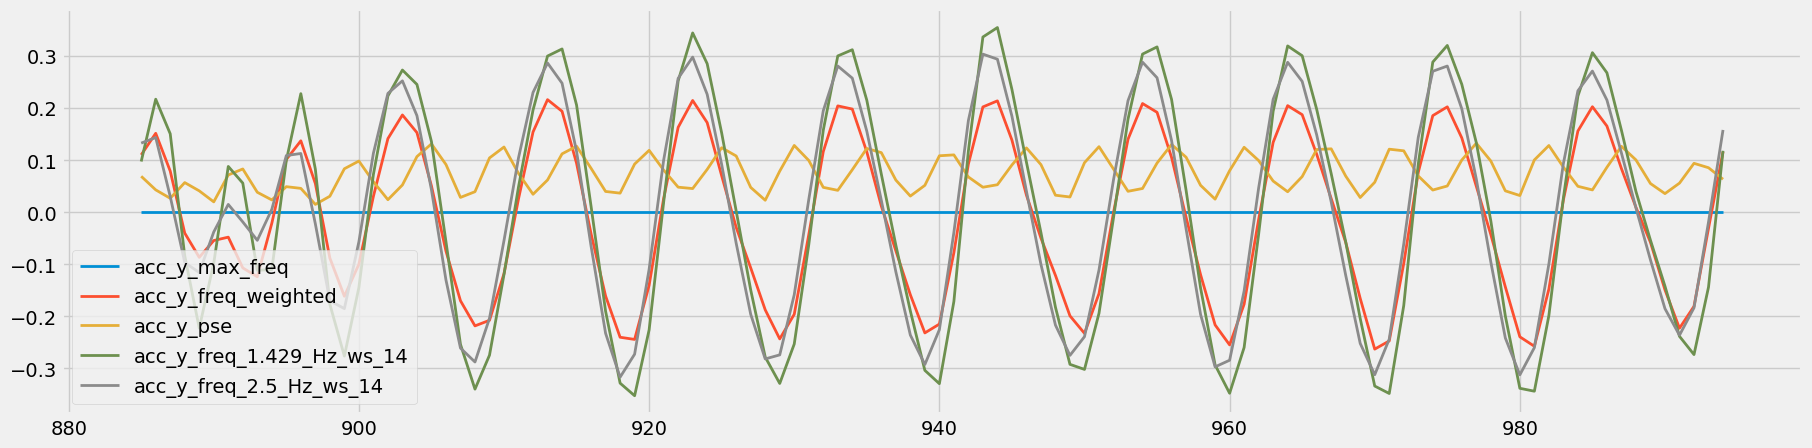

In [233]:
subset = df_freq[df_freq["set"] == 15]
subset[["acc_y"]].plot()
subset[
    [
        "acc_y_max_freq",
        "acc_y_freq_weighted",
        "acc_y_pse",
        "acc_y_freq_1.429_Hz_ws_14",
        "acc_y_freq_2.5_Hz_ws_14",
    ]
].plot()

df_freq_list = []
for s in df_freq["set"].unique():
    print(f"Applying Fourier transformations to set {s}")
    subset = df_freq[df_freq["set"] == s].reset_index(drop=True).copy()
    subset = FreqAbs.abstract_frequency(subset, predictor_columns, ws, fs)
    df_freq_list.append(subset)

df_freq = pd.concat(df_freq_list).set_index("epoch (ms)",drop=True)

In [234]:
df_freq

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,...,gyr_r_freq_weighted,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:05.200,0.013501,0.977022,-0.070982,-1.900465,2.437780,0.940880,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.400,-0.004111,0.962269,-0.075309,1.437860,-0.522120,0.476150,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.600,-0.014143,0.966368,-0.074978,1.633730,-2.981339,1.302906,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.800,-0.013047,0.979343,-0.074482,1.092197,-3.156357,0.501259,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:06.000,-0.010429,0.966609,-0.088632,5.070302,0.248676,-5.951031,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,...,-0.449883,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781
2019-01-20 17:33:27.200,-0.046788,-0.986139,-0.055736,2.208068,-3.456089,0.133057,E,row,medium,90,...,0.348761,0.412147,294.931283,-27.473656,23.739499,77.708240,-30.337110,16.231365,6.125870,17.080351
2019-01-20 17:33:27.400,-0.045416,-1.026145,-0.056200,-2.408598,-1.581380,1.525886,E,row,medium,90,...,0.535414,0.386193,267.453025,-39.305852,19.555288,40.143937,31.341136,25.527700,19.029846,10.521143


In [235]:
df_freq = pd.concat(df_freq_list).set_index("epoch (ms)",drop=True)

In [236]:
df_freq

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,...,gyr_r_freq_weighted,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:05.200,0.013501,0.977022,-0.070982,-1.900465,2.437780,0.940880,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.400,-0.004111,0.962269,-0.075309,1.437860,-0.522120,0.476150,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.600,-0.014143,0.966368,-0.074978,1.633730,-2.981339,1.302906,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:05.800,-0.013047,0.979343,-0.074482,1.092197,-3.156357,0.501259,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-11 15:08:06.000,-0.010429,0.966609,-0.088632,5.070302,0.248676,-5.951031,B,bench,heavy,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,...,-0.449883,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781
2019-01-20 17:33:27.200,-0.046788,-0.986139,-0.055736,2.208068,-3.456089,0.133057,E,row,medium,90,...,0.348761,0.412147,294.931283,-27.473656,23.739499,77.708240,-30.337110,16.231365,6.125870,17.080351
2019-01-20 17:33:27.400,-0.045416,-1.026145,-0.056200,-2.408598,-1.581380,1.525886,E,row,medium,90,...,0.535414,0.386193,267.453025,-39.305852,19.555288,40.143937,31.341136,25.527700,19.029846,10.521143


In [237]:
#dealing with overlapping windows

In [238]:
df_freq=df_freq.dropna()

In [239]:
df_freq=df_freq.iloc[::2]

In [240]:
df_freq

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,...,gyr_r_freq_weighted,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:08.000,-0.164924,0.865523,-0.178538,-20.541984,-8.226941,21.708715,B,bench,heavy,30,...,-1.045314,0.348493,182.101298,-22.460551,8.212900,12.208705,-18.398900,2.046792,-34.381447,-14.045145
2019-01-11 15:08:08.400,-0.037702,0.893562,-0.054992,-8.757968,-3.388710,5.934664,B,bench,heavy,30,...,-0.436200,0.366945,218.077345,1.196483,-59.149485,-31.789010,-5.715577,12.827112,1.699779,-0.802390
2019-01-11 15:08:08.800,-0.050594,0.971761,-0.036645,6.755364,-0.667937,-3.858589,B,bench,heavy,30,...,-0.394054,0.250244,224.788131,-5.519015,-25.951304,9.344700,1.411426,-39.945304,13.773509,-6.842649
2019-01-11 15:08:09.200,-0.054443,0.995092,-0.034129,-3.135521,-4.056549,5.582744,B,bench,heavy,30,...,0.497252,0.477223,208.077866,-29.385794,50.648931,11.469258,5.707674,35.408932,18.023310,0.586241
2019-01-11 15:08:09.600,-0.039912,0.883784,-0.060126,15.707099,5.334875,-11.553838,B,bench,heavy,30,...,-0.441889,0.432201,191.164632,-28.076080,34.138705,0.052550,11.161164,9.485386,-22.408690,-29.121987
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:26.200,0.058850,-0.909458,0.108233,-29.215392,5.558830,13.450505,E,row,medium,90,...,-0.545691,0.218648,340.057969,11.001737,-9.070391,35.790142,-44.934231,-19.424527,-16.025378,-21.283505
2019-01-20 17:33:26.600,-0.018615,-1.191105,-0.097478,-10.724922,0.437615,7.609956,E,row,medium,90,...,0.384854,0.181643,340.254610,8.561735,-1.119536,-19.978604,37.057462,36.872676,20.891222,8.593489
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,...,-0.449883,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781


In [241]:
#clustring

In [252]:
df_cluster=df_freq.copy()
cluster_columns=["acc_x","acc_y","acc_z"]
k_values=range(2,10)
inertias=[]
for k in k_values:
    subset = df_cluster[cluster_colums]
    Kmeans=KMeans(n_clusters=k,n_init=20,random_state=0)
    cluster_labels  = Kmeans.fit_predict(subset)
    inertias.append(Kmeans.inertia_)

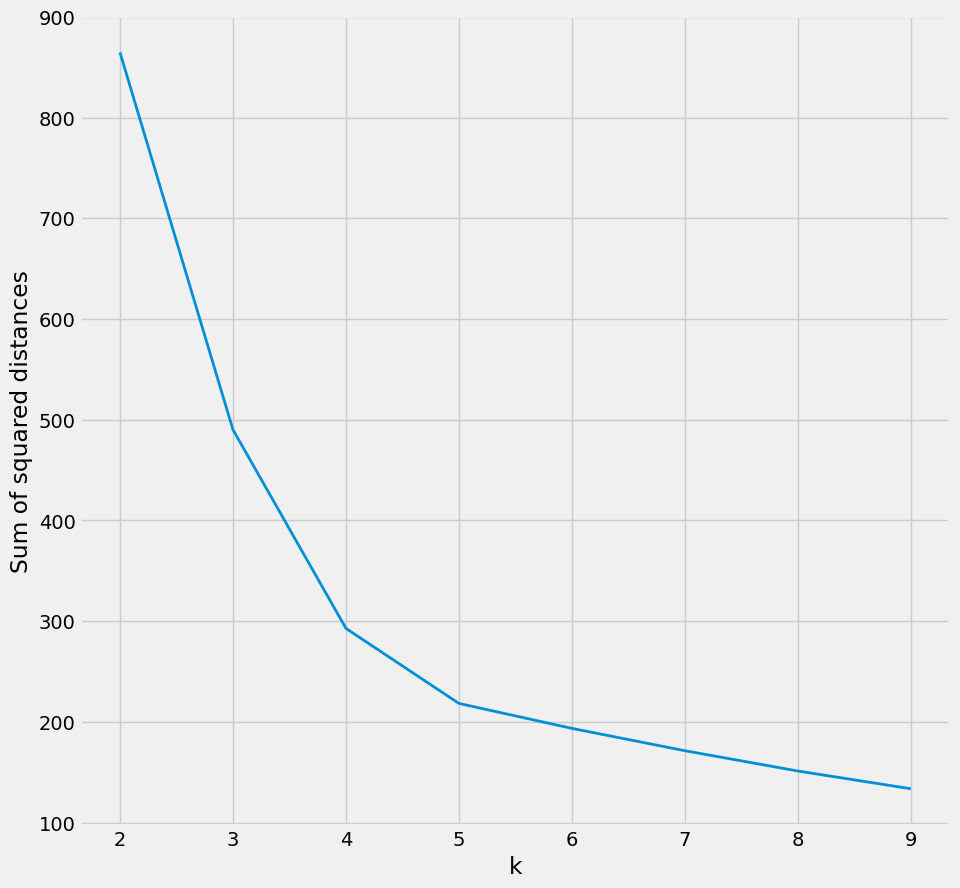

In [253]:
plt.figure(figsize=(10, 10))
plt.plot(k_values, inertias)
plt.xlabel("k")
plt.ylabel("Sum of squared distances")
plt.show()

In [254]:
kmeans = KMeans(n_clusters=5, n_init=20, random_state=0)
subset = df_cluster[cluster_columns]
df_cluster["cluster"] = kmeans.fit_predict(subset)

In [255]:
df_cluster

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,...,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14,cluster
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:08.000,-0.164924,0.865523,-0.178538,-20.541984,-8.226941,21.708715,B,bench,heavy,30,...,0.348493,182.101298,-22.460551,8.212900,12.208705,-18.398900,2.046792,-34.381447,-14.045145,0
2019-01-11 15:08:08.400,-0.037702,0.893562,-0.054992,-8.757968,-3.388710,5.934664,B,bench,heavy,30,...,0.366945,218.077345,1.196483,-59.149485,-31.789010,-5.715577,12.827112,1.699779,-0.802390,0
2019-01-11 15:08:08.800,-0.050594,0.971761,-0.036645,6.755364,-0.667937,-3.858589,B,bench,heavy,30,...,0.250244,224.788131,-5.519015,-25.951304,9.344700,1.411426,-39.945304,13.773509,-6.842649,0
2019-01-11 15:08:09.200,-0.054443,0.995092,-0.034129,-3.135521,-4.056549,5.582744,B,bench,heavy,30,...,0.477223,208.077866,-29.385794,50.648931,11.469258,5.707674,35.408932,18.023310,0.586241,0
2019-01-11 15:08:09.600,-0.039912,0.883784,-0.060126,15.707099,5.334875,-11.553838,B,bench,heavy,30,...,0.432201,191.164632,-28.076080,34.138705,0.052550,11.161164,9.485386,-22.408690,-29.121987,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:26.200,0.058850,-0.909458,0.108233,-29.215392,5.558830,13.450505,E,row,medium,90,...,0.218648,340.057969,11.001737,-9.070391,35.790142,-44.934231,-19.424527,-16.025378,-21.283505,4
2019-01-20 17:33:26.600,-0.018615,-1.191105,-0.097478,-10.724922,0.437615,7.609956,E,row,medium,90,...,0.181643,340.254610,8.561735,-1.119536,-19.978604,37.057462,36.872676,20.891222,8.593489,1
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,...,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781,1


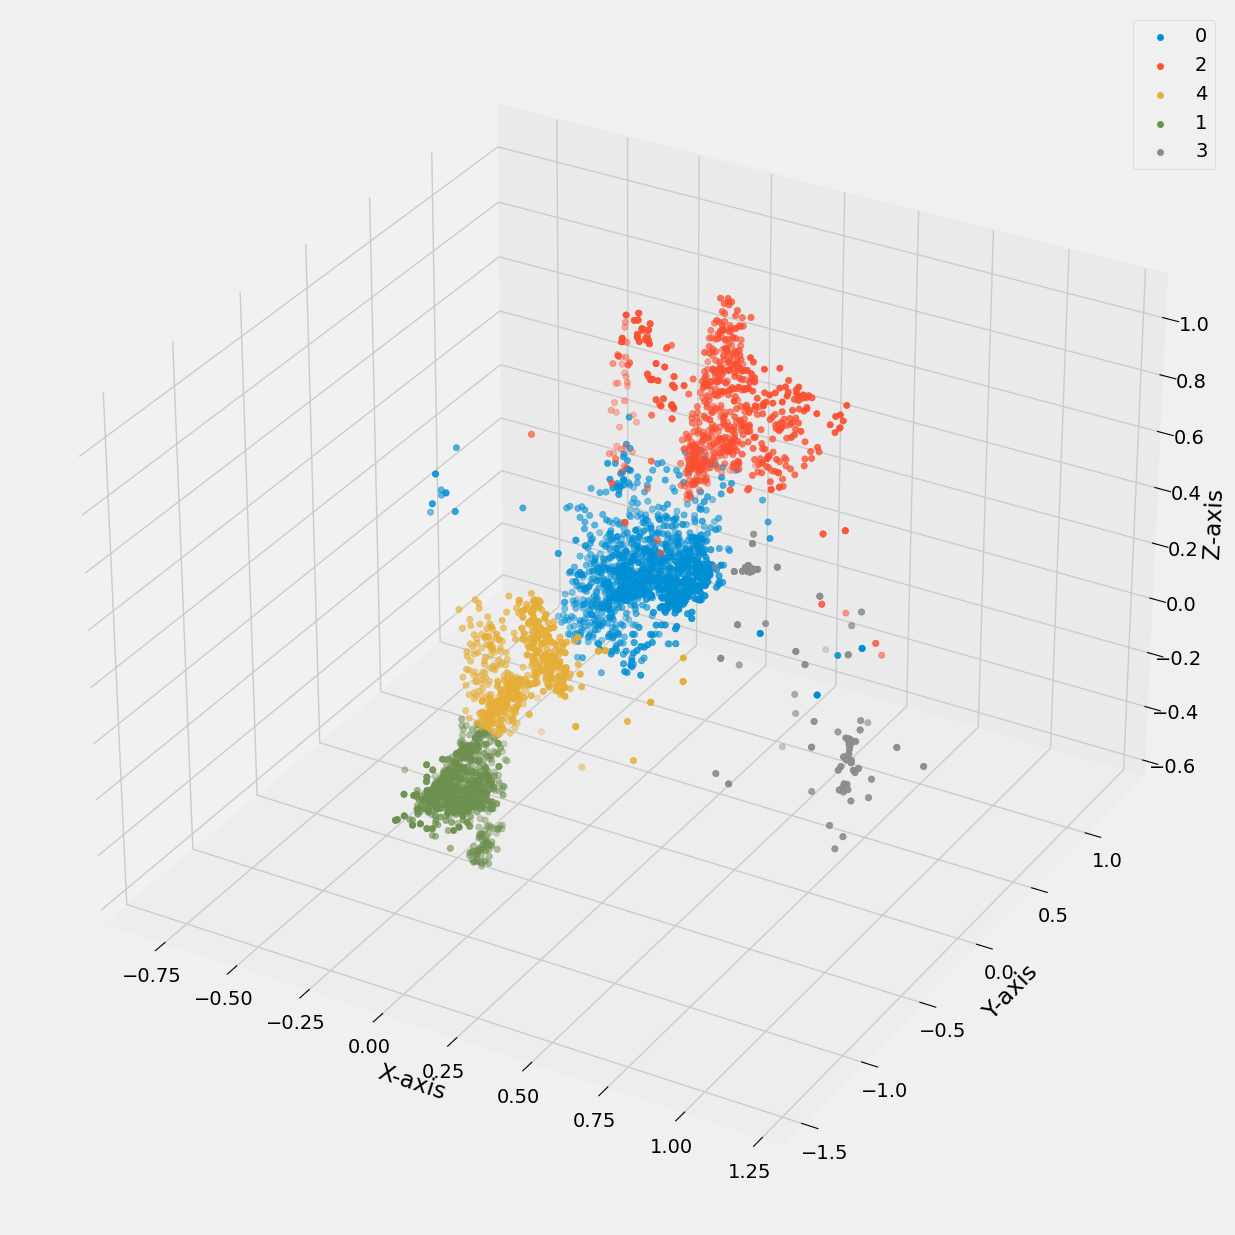

In [256]:
# Plot Clusters
fig = plt.figure(figsize=(15, 15))
ax = fig.add_subplot(projection="3d")
for c in df_cluster["cluster"].unique():
    subset = df_cluster[df_cluster["cluster"] == c]
    ax.scatter(subset["acc_x"], subset["acc_y"], subset["acc_z"], label=c)
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")
plt.legend()
plt.show()

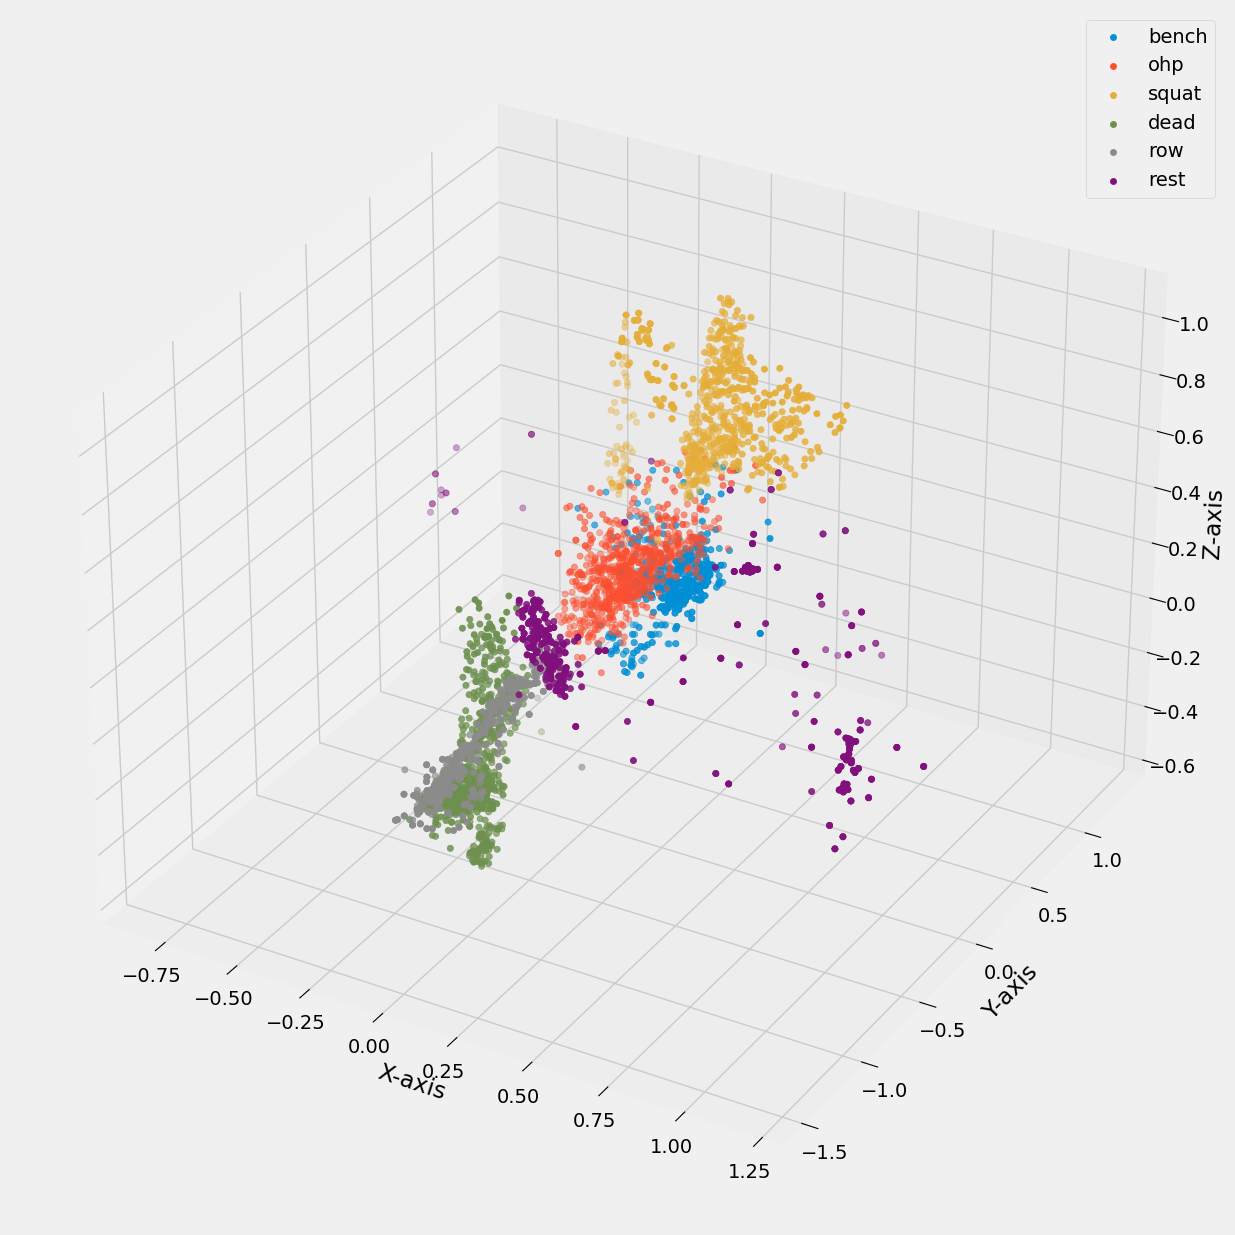

In [257]:
# Plot Clusters
fig = plt.figure(figsize=(15, 15))
ax = fig.add_subplot(projection="3d")
for c in df_cluster["label"].unique():
    subset = df_cluster[df_cluster["label"] == c]
    ax.scatter(subset["acc_x"], subset["acc_y"], subset["acc_z"], label=c)
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")
plt.legend()
plt.show()

In [258]:
df_cluster.to_pickle("../../data/interim/03_data_features.pkl")

In [259]:
df_cluster

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,...,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14,cluster
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:08.000,-0.164924,0.865523,-0.178538,-20.541984,-8.226941,21.708715,B,bench,heavy,30,...,0.348493,182.101298,-22.460551,8.212900,12.208705,-18.398900,2.046792,-34.381447,-14.045145,0
2019-01-11 15:08:08.400,-0.037702,0.893562,-0.054992,-8.757968,-3.388710,5.934664,B,bench,heavy,30,...,0.366945,218.077345,1.196483,-59.149485,-31.789010,-5.715577,12.827112,1.699779,-0.802390,0
2019-01-11 15:08:08.800,-0.050594,0.971761,-0.036645,6.755364,-0.667937,-3.858589,B,bench,heavy,30,...,0.250244,224.788131,-5.519015,-25.951304,9.344700,1.411426,-39.945304,13.773509,-6.842649,0
2019-01-11 15:08:09.200,-0.054443,0.995092,-0.034129,-3.135521,-4.056549,5.582744,B,bench,heavy,30,...,0.477223,208.077866,-29.385794,50.648931,11.469258,5.707674,35.408932,18.023310,0.586241,0
2019-01-11 15:08:09.600,-0.039912,0.883784,-0.060126,15.707099,5.334875,-11.553838,B,bench,heavy,30,...,0.432201,191.164632,-28.076080,34.138705,0.052550,11.161164,9.485386,-22.408690,-29.121987,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:26.200,0.058850,-0.909458,0.108233,-29.215392,5.558830,13.450505,E,row,medium,90,...,0.218648,340.057969,11.001737,-9.070391,35.790142,-44.934231,-19.424527,-16.025378,-21.283505,4
2019-01-20 17:33:26.600,-0.018615,-1.191105,-0.097478,-10.724922,0.437615,7.609956,E,row,medium,90,...,0.181643,340.254610,8.561735,-1.119536,-19.978604,37.057462,36.872676,20.891222,8.593489,1
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,E,row,medium,90,...,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781,1
